Date
2016-01-04    42141.0
2016-01-05    42419.0
2016-01-06    41773.0
2016-01-07    40695.0
2016-01-08    40612.0
Name: Ibovespa, dtype: float64

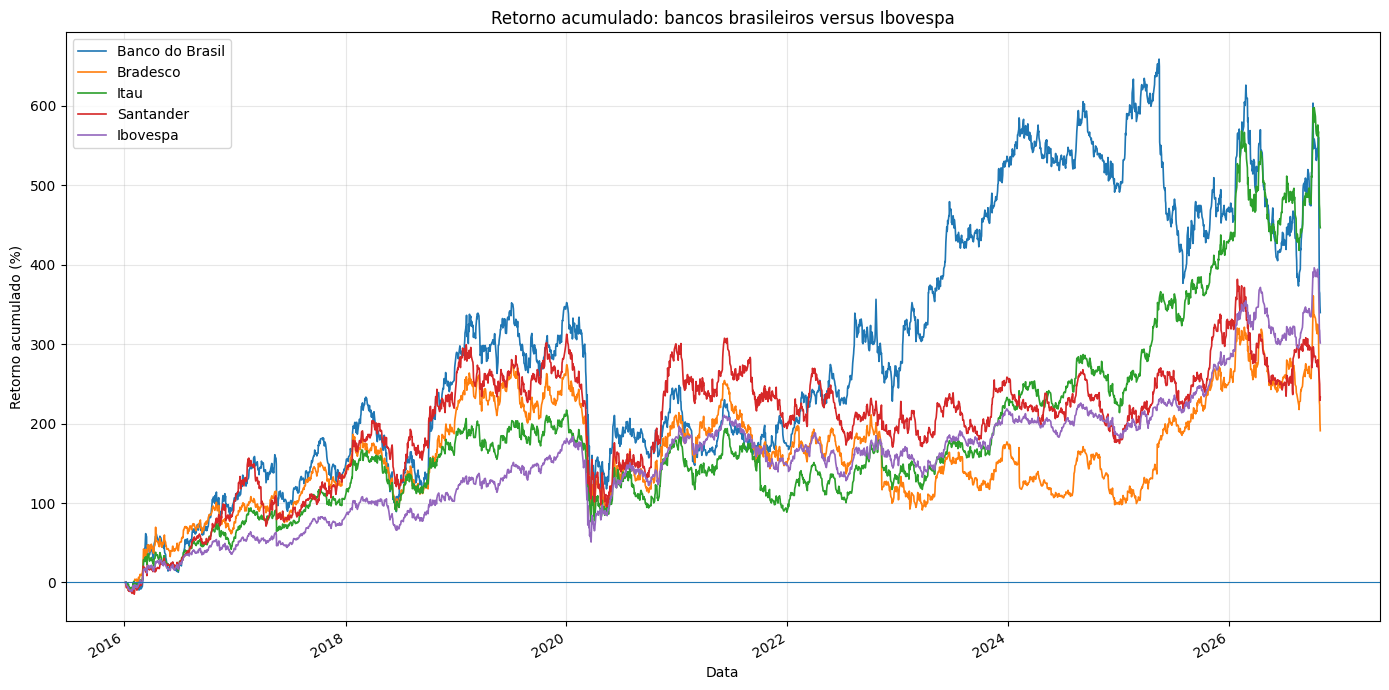

,Retorno acumulado (%),Volatilidade anualizada (%),Maximum drawdown (%),Correlação com Ibovespa
Itau,446.52,30.04,-44.34,0.80
Banco do Brasil,339.71,39.13,-58.29,0.78
Santander,233.10,32.95,-52.51,0.73
Bradesco,191.01,35.08,-52.77,0.80


In [2]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# Definir os bancos e seus códigos de negociação
bancos = {
    "Itau": "ITUB4.SA",
    "Bradesco": "BBDC4.SA",
    "Santander": "SANB11.SA",
    "Banco do Brasil": "BBAS3.SA",
}

# Definir o início do período analisado
data_inicio = "2016-01-01"

# Baixar os preços históricos
dados = yf.download(
    list(bancos.values()),
    start=data_inicio,
    auto_adjust=True,
    progress=False
)
# Selecionar os preços de fechamento ajustados
precos = dados["Close"].rename(
    columns={
        ticker: nome
        for nome, ticker in bancos.items()
    }
)

# Organizar cronologicamente
precos = precos.sort_index()

# Calcular o retorno diário de cada ação
retornos = precos.pct_change(fill_method=None)

# Calcular o retorno acumulado desde o início da amostra
retorno_acumulado = (
    precos.div(precos.iloc[0]) - 1)

# Calcular o desvio-padrão dos retornos diários
volatilidade_diaria = retornos.std()

# Anualizar usando a convenção de 252 pregões por ano
volatilidade_anualizada = (
    volatilidade_diaria * np.sqrt(252) * 100)

# Organizar os resultados em uma tabela
resumo_volatilidade = (
    volatilidade_anualizada
    .rename("Volatilidade anualizada (%)")
    .to_frame()
)

# Identificar o maior preço alcançado até cada data
picos = precos.cummax()

# Calcular a queda em relação ao pico acumulado
drawdowns = precos.div(picos) - 1

# Identificar a maior queda de cada ação
max_drawdown = drawdowns.min() * 100

# Organizar os resultados em uma tabela
resumo_drawdown = (
    max_drawdown
    .rename("Maximum drawdown (%)")
    .to_frame()
)

# Combinar os indicadores calculados
comparacao_risco = pd.concat(
    [
        resumo_volatilidade,
        resumo_drawdown
    ],
    axis=1
)

# Baixar os dados do Ibovespa
dados_ibov = yf.download(
    "^BVSP",
    start=data_inicio,
    auto_adjust=True,
    progress=False
)

# Selecionar os preços de fechamento do Ibovespa
precos_ibov = dados_ibov["Close"]

# Garantir que temos uma Series, e não um DataFrame
if isinstance(precos_ibov, pd.DataFrame):
    precos_ibov = precos_ibov.iloc[:, 0]

# Limpar e organizar os dados
precos_ibov = (
    precos_ibov
    .dropna()
    .sort_index()
)

# Definir o nome da série
precos_ibov.name = "Ibovespa"

# Calcular os retornos diários do índice
retorno_ibov = precos_ibov.pct_change(
    fill_method=None
)

# Conferir o resultado
display(precos_ibov.head())

# Preparar a série histórica
precos_ibov = (
    precos_ibov
    .dropna()
    .sort_index()
    .rename("Ibovespa")
)

# Combinar os retornos dos bancos e do Ibovespa pelas datas
retornos_com_ibov = pd.concat(
    [
        retornos,
        retorno_ibov
    ],
    axis=1
)

# Calcular a matriz de correlação
matriz_correlacao = retornos_com_ibov.corr()

# Selecionar a relação de cada banco com o Ibovespa
correlacao_com_ibov = (
    matriz_correlacao["Ibovespa"]
    .drop("Ibovespa")
)

# Organizar os resultados
resumo_correlacao = (
    correlacao_com_ibov
    .rename("Correlação com Ibovespa")
    .to_frame()
    .sort_values(
        by="Correlação com Ibovespa",
        ascending=False
    )
)

# Calcular o retorno acumulado do Ibovespa
retorno_acumulado_ibov = (
    precos_ibov / precos_ibov.iloc[0] - 1
)

# Juntar os retornos acumulados usando as datas em comum
comparacao_desempenho = retorno_acumulado.join(
    retorno_acumulado_ibov.rename("Ibovespa"),
    how="inner"
)

# Converter para porcentagem e construir o gráfico
ax = (
    comparacao_desempenho * 100
).plot(
    figsize=(14, 7),
    linewidth=1.2
)

ax.set_title(
    "Retorno acumulado: bancos brasileiros versus Ibovespa"
)
ax.set_xlabel("Data")
ax.set_ylabel("Retorno acumulado (%)")
ax.axhline(y=0, linewidth=0.8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Retorno acumulado mais recente de cada banco
retorno_final = (
    retorno_acumulado.iloc[-1] * 100
).rename("Retorno acumulado (%)")

# Reunir todas as métricas
resumo_final = pd.concat(
    [
        retorno_final,
        resumo_volatilidade["Volatilidade anualizada (%)"],
        resumo_drawdown["Maximum drawdown (%)"],
        resumo_correlacao["Correlação com Ibovespa"]
    ],
    axis=1
)

# Ordenar pelo retorno acumulado
resumo_final = resumo_final.sort_values(
    by="Retorno acumulado (%)",
    ascending=False
)

display(resumo_final.round(2))